# Analisis Sentimen Ulasan Pengguna Aplikasi Gojek di Google Play Store

Notebook ini dibuat untuk memenuhi kriteria submission:
1. Data diperoleh melalui scraping mandiri menggunakan Python.
2. Dataset minimal 3.000 sampel.
3. Melakukan pelabelan data dan ekstraksi fitur.
4. Menggunakan algoritma machine learning.
5. Evaluasi model dengan target akurasi testing minimal 85%.

Objek penelitian: **Aplikasi Gojek**  
Sumber data: **Google Play Store**  
Metode ekstraksi fitur: **TF-IDF**  
Model machine learning: **Naive Bayes, Logistic Regression, Linear SVM, Random Forest**

## 1. Import Library

In [14]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from google_play_scraper import Sort, reviews
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings('ignore')
sns.set()

## 2. Load Data

In [ ]:
# Load data dari file CSV
df_raw = pd.read_csv('gojek_reviews_raw.csv', encoding='utf-8-sig')
print('File gojek_reviews_raw.csv berhasil dimuat.')
print('Jumlah data:', len(df_raw))
print('\nKolom yang tersedia:')
print(df_raw.columns.tolist())
print('\nPreview data:')
print(df_raw.head())

## 3. Memilih Kolom yang Digunakan

Kolom utama yang digunakan:
- `content`: isi ulasan pengguna
- `score`: rating bintang dari pengguna
- `at`: tanggal review

In [ ]:
df = df_raw[['userName', 'content', 'score', 'thumbsUpCount', 'at']].copy()
df = df.dropna(subset=['content', 'score'])
df.head()

## 5. Eksplorasi Awal Dataset

In [17]:
print('Ukuran dataset:', df.shape)
print('\nInformasi dataset:')
print(df.info())

print('\nDistribusi rating:')
print(df['score'].value_counts().sort_index())

Ukuran dataset: (8000, 5)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   userName       8000 non-null   str  
 1   content        8000 non-null   str  
 2   score          8000 non-null   int64
 3   thumbsUpCount  8000 non-null   int64
 4   at             8000 non-null   str  
dtypes: int64(2), str(3)
memory usage: 312.6 KB
None

Distribusi rating:
score
1    2215
2     391
3     355
4     392
5    4647
Name: count, dtype: int64


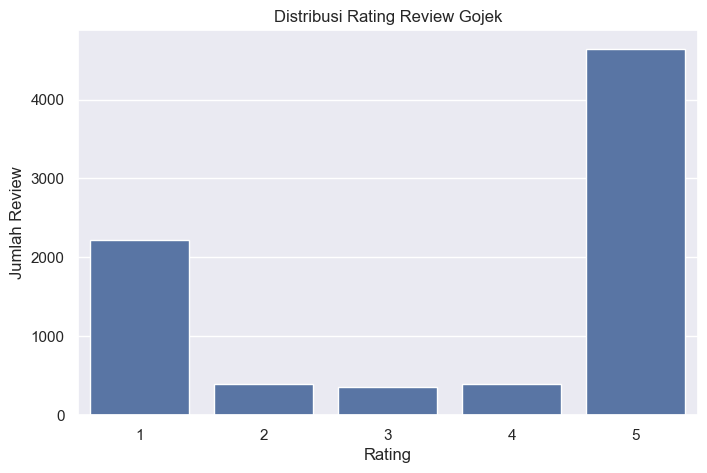

In [18]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='score')
plt.title('Distribusi Rating Review Gojek')
plt.xlabel('Rating')
plt.ylabel('Jumlah Review')
plt.show()

## 6. Pelabelan Sentimen

Strategi pelabelan:

| Rating | Label |
|---|---|
| 1 dan 2 | Negatif |
| 3 | Dihapus karena ambigu |
| 4 dan 5 | Positif |

Rating 3 dihapus karena sering mengandung opini campuran sehingga dapat menurunkan performa model.

In [19]:
def label_sentiment(score):
    if score <= 2:
        return 'negatif'
    elif score >= 4:
        return 'positif'
    else:
        return 'netral'

df['sentiment'] = df['score'].apply(label_sentiment)

# Menghapus data netral
df = df[df['sentiment'] != 'netral'].copy()

print('Jumlah data setelah rating netral dihapus:', len(df))
print(df['sentiment'].value_counts())

Jumlah data setelah rating netral dihapus: 7645
sentiment
positif    5039
negatif    2606
Name: count, dtype: int64


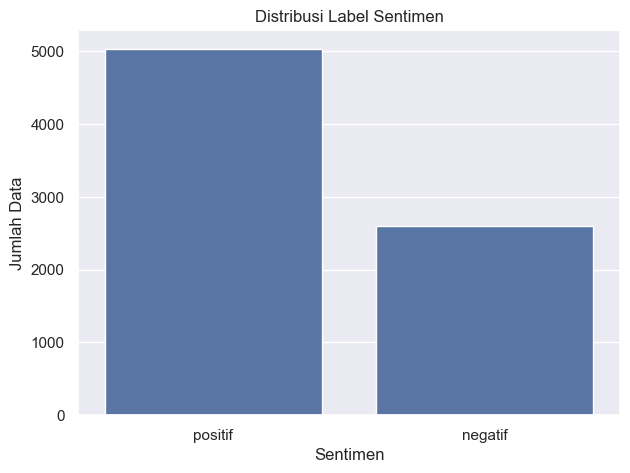

In [20]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='sentiment')
plt.title('Distribusi Label Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Data')
plt.show()

## 7. Cleaning dan Preprocessing Teks

Tahapan preprocessing:
1. Case folding
2. Menghapus URL, mention, hashtag, angka, tanda baca, dan karakter tidak penting
3. Normalisasi kata tidak baku sederhana
4. Stopword removal Bahasa Indonesia
5. Stemming Bahasa Indonesia menggunakan Sastrawi

In [ ]:
# Inisialisasi stopword dan stemmer
stop_factory = StopWordRemoverFactory()
stopwords_indonesia = set(stop_factory.get_stop_words())

# Tambahan stopword yang sering muncul tetapi kurang bermakna
custom_stopwords = {
    'gojek', 'gojeknya', 'app', 'aplikasi', 'apk', 'nya', 'yg', 'ga', 'gak', 'nggak',
    'aja', 'sih', 'dong', 'deh', 'nih', 'banget', 'bgt', 'kak', 'min'
}

stopwords_indonesia = stopwords_indonesia.union(custom_stopwords)

factory = StemmerFactory()
stemmer = factory.create_stemmer()

# Kamus normalisasi sederhana
normalization_dict = {
    'gk': 'tidak',
    'ga': 'tidak',
    'gak': 'tidak',
    'nggak': 'tidak',
    'tdk': 'tidak',
    'tak': 'tidak',
    'bgt': 'banget',
    'bangettt': 'banget',
    'mantappp': 'mantap',
    'mantapp': 'mantap',
    'apk': 'aplikasi',
    'app': 'aplikasi',
    'lemottt': 'lemot',
    'lemotnya': 'lemot',
    'erorr': 'error',
    'erroor': 'error',
    'errorr': 'error',
    'baguss': 'bagus',
    'bagusss': 'bagus',
    'parahh': 'parah',
    'kecewaaa': 'kecewa',
    'driver': 'pengemudi',
    'drivernya': 'pengemudi',
    'orderan': 'pesanan',
    'cancel': 'batal',
    'cancelled': 'batal',
    'cs': 'customer service'
}

def normalize_words(text):
    words = text.split()
    normalized_words = [normalization_dict[word] if word in normalization_dict else word for word in words]
    return ' '.join(normalized_words)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', ' ', text)
    text = re.sub(r'@\w+|#\w+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def remove_stopwords(text):
    words = text.split()
    filtered_words = [word for word in words if word not in stopwords_indonesia]
    return ' '.join(filtered_words)

def preprocess_text(text):
    text = clean_text(text)
    text = normalize_words(text)
    text = remove_stopwords(text)
    text = stemmer.stem(text)
    return text

df['clean_text'] = df['content'].apply(preprocess_text)

df[['content', 'clean_text', 'sentiment']].head(10)

## 8. Menghapus Data Kosong Setelah Preprocessing

In [22]:
df = df[df['clean_text'].str.strip() != ''].copy()
df = df.drop_duplicates(subset=['clean_text'])

print('Jumlah data akhir:', len(df))
print(df['sentiment'].value_counts())

Jumlah data akhir: 5113
sentiment
positif    2582
negatif    2531
Name: count, dtype: int64


In [23]:
if len(df) >= 3000:
    print('Dataset memenuhi kriteria minimal 3.000 sampel.')
else:
    print('Dataset belum memenuhi 3.000 sampel. Silakan tambah jumlah scraping.')

Dataset memenuhi kriteria minimal 3.000 sampel.


In [24]:
df.to_csv('gojek_reviews_clean_labeled.csv', index=False, encoding='utf-8-sig')
print('File gojek_reviews_clean_labeled.csv berhasil disimpan.')

File gojek_reviews_clean_labeled.csv berhasil disimpan.


## 9. Split Data Training dan Testing

Data dibagi menjadi:
- 80% training
- 20% testing



In [25]:
X = df['clean_text']
y = df['sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Jumlah data training:', len(X_train))
print('Jumlah data testing:', len(X_test))
print('\nDistribusi training:')
print(y_train.value_counts())
print('\nDistribusi testing:')
print(y_test.value_counts())

Jumlah data training: 4090
Jumlah data testing: 1023

Distribusi training:
sentiment
positif    2065
negatif    2025
Name: count, dtype: int64

Distribusi testing:
sentiment
positif    517
negatif    506
Name: count, dtype: int64


## 10. Training Beberapa Model Machine Learning

Model yang diuji:
1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear SVM
4. Random Forest

Fitur teks diekstraksi menggunakan TF-IDF dengan unigram dan bigram.

In [26]:
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear SVM': LinearSVC(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
}

results = []

trained_pipelines = {}

for model_name, model in models.items():
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(
            max_features=10000,
            ngram_range=(1,2),
            min_df=2,
            max_df=0.9
        )),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        'Model': model_name,
        'Accuracy': accuracy
    })

    trained_pipelines[model_name] = pipeline

    print('='*60)
    print(model_name)
    print('Accuracy:', accuracy)
    print(classification_report(y_test, y_pred))

Naive Bayes
Accuracy: 0.8963831867057673
              precision    recall  f1-score   support

     negatif       0.86      0.94      0.90       506
     positif       0.93      0.86      0.89       517

    accuracy                           0.90      1023
   macro avg       0.90      0.90      0.90      1023
weighted avg       0.90      0.90      0.90      1023

Logistic Regression
Accuracy: 0.8973607038123167
              precision    recall  f1-score   support

     negatif       0.90      0.90      0.90       506
     positif       0.90      0.90      0.90       517

    accuracy                           0.90      1023
   macro avg       0.90      0.90      0.90      1023
weighted avg       0.90      0.90      0.90      1023

Linear SVM
Accuracy: 0.8983382209188661
              precision    recall  f1-score   support

     negatif       0.90      0.90      0.90       506
     positif       0.90      0.90      0.90       517

    accuracy                           0.90      102

## 11. Perbandingan Akurasi Model

In [27]:
results_df = pd.DataFrame(results).sort_values(by='Accuracy', ascending=False)
results_df

,Model,Accuracy
2,Linear SVM,0.898338
1,Logistic Regression,0.897361
0,Naive Bayes,0.896383
3,Random Forest,0.876833


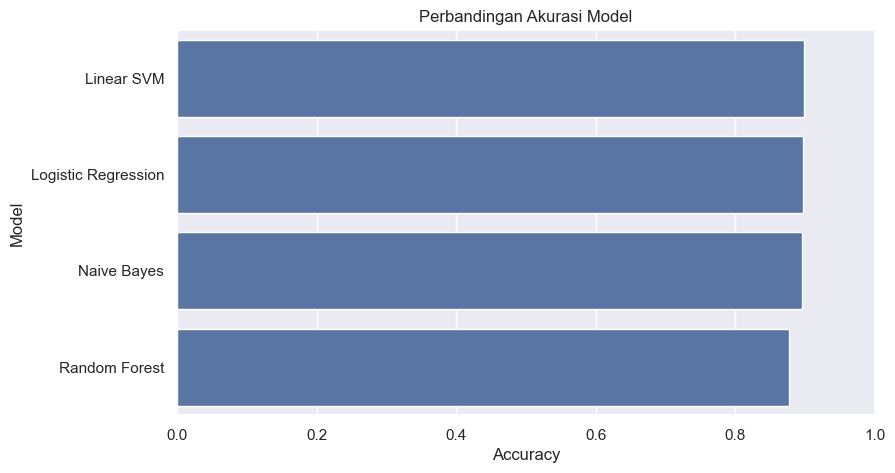

In [28]:
plt.figure(figsize=(9,5))
sns.barplot(data=results_df, x='Accuracy', y='Model')
plt.title('Perbandingan Akurasi Model')
plt.xlabel('Accuracy')
plt.ylabel('Model')
plt.xlim(0, 1)
plt.show()

## 12. Memilih Model Terbaik

In [29]:
best_model_name = results_df.iloc[0]['Model']
best_accuracy = results_df.iloc[0]['Accuracy']
best_pipeline = trained_pipelines[best_model_name]

print('Model terbaik:', best_model_name)
print('Akurasi testing:', best_accuracy)

if best_accuracy >= 0.85:
    print('Model sudah memenuhi kriteria akurasi minimal 85%.')
else:
    print('Model belum mencapai 85%. Perlu tuning atau perbaikan preprocessing.')

Model terbaik: Linear SVM
Akurasi testing: 0.8983382209188661
Model sudah memenuhi kriteria akurasi minimal 85%.


## 13. Confusion Matrix Model Terbaik

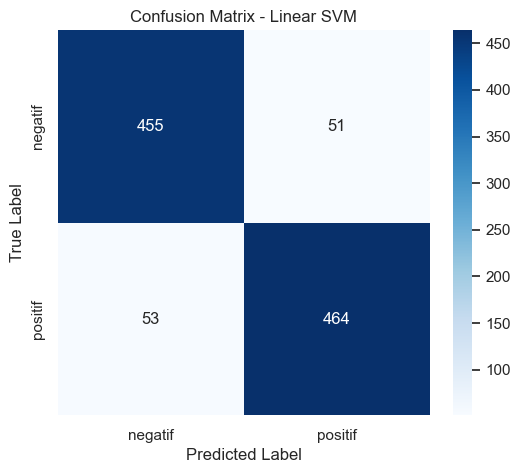

              precision    recall  f1-score   support

     negatif       0.90      0.90      0.90       506
     positif       0.90      0.90      0.90       517

    accuracy                           0.90      1023
   macro avg       0.90      0.90      0.90      1023
weighted avg       0.90      0.90      0.90      1023



In [30]:
y_pred_best = best_pipeline.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best, labels=['negatif', 'positif'])

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['negatif', 'positif'],
    yticklabels=['negatif', 'positif'],
    cmap='Blues'
)
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print(classification_report(y_test, y_pred_best))

## 14. Hyperparameter Tuning untuk Linear SVM




In [31]:
param_grid = {
    'tfidf__max_features': [5000, 10000, 15000],
    'tfidf__ngram_range': [(1,1), (1,2)],
    'model__C': [0.1, 1, 10]
}

svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(min_df=2, max_df=0.9)),
    ('model', LinearSVC(random_state=42))
])

grid_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best CV score:', grid_search.best_score_)

best_tuned_model = grid_search.best_estimator_
y_pred_tuned = best_tuned_model.predict(X_test)
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print('Akurasi testing setelah tuning:', tuned_accuracy)
print(classification_report(y_test, y_pred_tuned))

Fitting 3 folds for each of 18 candidates, totalling 54 fits
Best parameters: {'model__C': 0.1, 'tfidf__max_features': 5000, 'tfidf__ngram_range': (1, 1)}
Best CV score: 0.882395297016744
Akurasi testing setelah tuning: 0.9012707722385142
              precision    recall  f1-score   support

     negatif       0.91      0.89      0.90       506
     positif       0.90      0.91      0.90       517

    accuracy                           0.90      1023
   macro avg       0.90      0.90      0.90      1023
weighted avg       0.90      0.90      0.90      1023



## 15. Simpan Model dan Vectorizer

Model terbaik disimpan dalam format `.pkl`.

In [32]:


try:
    if tuned_accuracy > best_accuracy:
        final_model = best_tuned_model
        final_model_name = 'Tuned Linear SVM'
        final_accuracy = tuned_accuracy
    else:
        final_model = best_pipeline
        final_model_name = best_model_name
        final_accuracy = best_accuracy
except NameError:
    final_model = best_pipeline
    final_model_name = best_model_name
    final_accuracy = best_accuracy

joblib.dump(final_model, 'model_sentimen_gojek.pkl')

print('Model berhasil disimpan sebagai model_sentimen_gojek.pkl')
print('Final model:', final_model_name)
print('Final accuracy:', final_accuracy)

Model berhasil disimpan sebagai model_sentimen_gojek.pkl
Final model: Tuned Linear SVM
Final accuracy: 0.9012707722385142


## 16. Uji Prediksi Teks Baru

In [33]:
def predict_sentiment(text):
    clean = preprocess_text(text)
    prediction = final_model.predict([clean])[0]
    return prediction

contoh_ulasan = [
    'Aplikasi gojek sangat membantu dan drivernya ramah',
    'Aplikasi sering error dan pesanan saya dibatalkan terus',
    'Pelayanan bagus, proses cepat, sangat puas',
    'Sangat kecewa karena saldo hilang dan customer service lambat'
]

for ulasan in contoh_ulasan:
    print('Ulasan:', ulasan)
    print('Prediksi:', predict_sentiment(ulasan))
    print('-'*50)

Ulasan: Aplikasi gojek sangat membantu dan drivernya ramah
Prediksi: positif
--------------------------------------------------
Ulasan: Aplikasi sering error dan pesanan saya dibatalkan terus
Prediksi: negatif
--------------------------------------------------
Ulasan: Pelayanan bagus, proses cepat, sangat puas
Prediksi: positif
--------------------------------------------------
Ulasan: Sangat kecewa karena saldo hilang dan customer service lambat
Prediksi: negatif
--------------------------------------------------


## 17. Kesimpulan

Berdasarkan hasil penelitian, model analisis sentimen terhadap ulasan pengguna aplikasi Gojek berhasil dibuat menggunakan data hasil scraping dari Google Play Store. Data diberi label berdasarkan rating pengguna, kemudian dilakukan preprocessing teks dan ekstraksi fitur menggunakan TF-IDF. Beberapa algoritma machine learning dibandingkan untuk memperoleh model terbaik.

